## 03-Contextual Compression-上下文压缩

### 1. 是什么？
```
对检索后的文档进行过滤、抽取、摘要或压缩，以保留跟问题最相关的部分
```

### 2. 要解决什么问题？
```
① 检索到的内容过长
② 检索到的内容中，关键信息包含大量不相关的内容
```

### 3. 基本思路


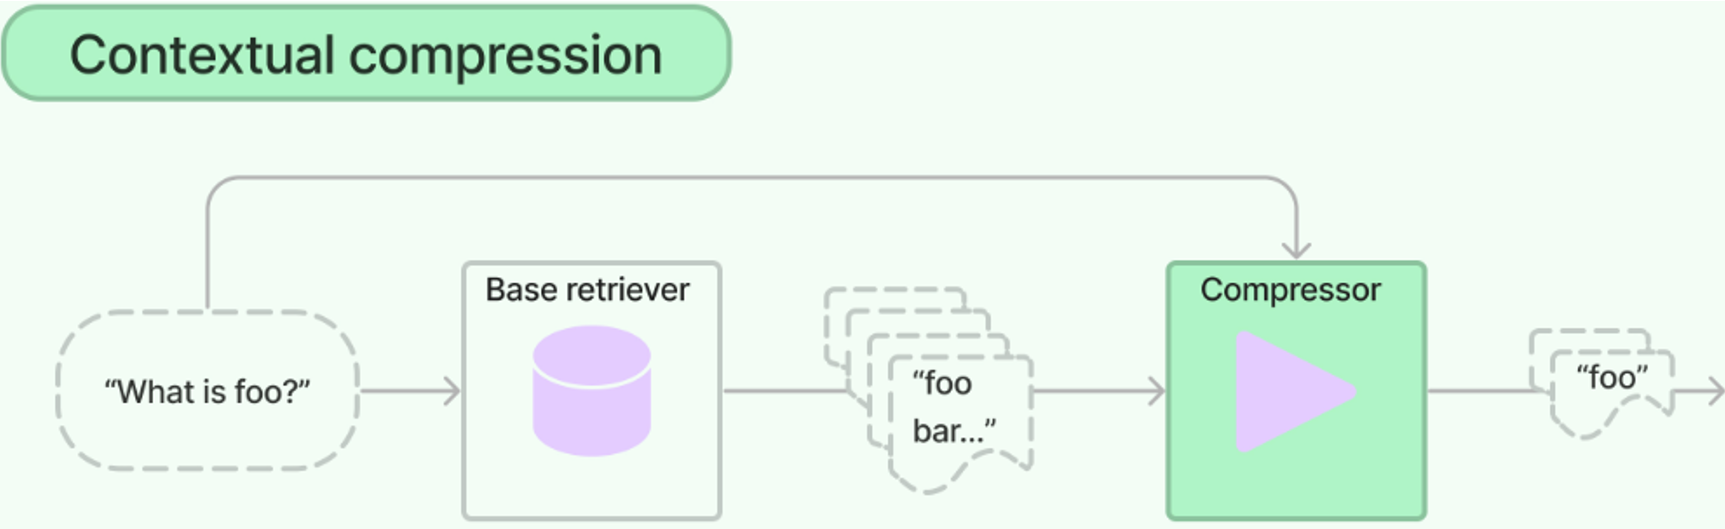

### 4. 代码实例

##### 对话模型

In [1]:
import os
from langchain_openai import ChatOpenAI
llm = deepseek = ChatOpenAI(api_key=os.getenv
("DEEPSEEK_API_KEY"), model="deepseek-v4-flash", base_url="https://api.deepseek.com")

##### 嵌入模型

In [2]:
from langchain_community.embeddings import DashScopeEmbeddings
embeddings_model = DashScopeEmbeddings(model="text-embedding-v4", dashscope_api_key=os.getenv("DASHSCOPE_API_KEY"))

# 通过本地ollama上运行的bge-m3做向量化, 使用需要关闭 代理/VPN
from langchain_ollama import OllamaEmbeddings
embeddings_model = OllamaEmbeddings(model="bge-m3")

##### 文档加载

In [3]:
from langchain_community.document_loaders import TextLoader
loader = TextLoader("../../data/deepseek百度百科.txt", encoding="utf-8")
docs = loader.load()
print(f"文章的长度：{len(docs[0].page_content)}")

文章的长度：20899


##### 文档切分

In [4]:
# 格式化输出内容
def pretty_print_docs(docs):
    print(
        f"\n{'-' * 100}\n".join(
            [f"Document {i+1}:\n\n" + d.page_content for i, d in enumerate(docs)]
        )
    )

In [5]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1024, chunk_overlap=100)
docs = text_splitter.split_documents(docs)
print(f"切分后的块数：{len(docs)} 个块")
pretty_print_docs(docs)

切分后的块数：27 个块
Document 1:

DeepSeek，全称杭州深度求索人工智能基础技术研究有限公司。DeepSeek是一家创新型科技公司，成立于2023年7月17日 ，使用数据蒸馏技术，得到更为精炼、有用的数据。由知名私募巨头幻方量化孕育而生，专注于开发先进的大语言模型（LLM）和相关技术。注册地址：浙江省杭州市拱墅区环城北路169号汇金国际大厦西1幢1201室。法定代表人为裴湉，经营范围包括技术服务、技术开发、软件开发等。
2024年1月5日至6月，相继发布DeepSeek LLM、DeepSeek-Coder、DeepSeekMath、DeepSeek-VL、DeepSeek-V2、DeepSeek-Coder-V2模型。 2024年9月5日，更新API支持文档，宣布合并DeepSeek Coder V2和DeepSeek V2 Chat，推出DeepSeek V2.5。12月13日，发布DeepSeek-VL2。12月26日，正式上线DeepSeek-V3首个版本并同步开源。2025年1月31日，英伟达宣布DeepSeek-R1模型登陆NVIDIANIM。同一时段内，亚马逊和微软也接入DeepSeek-R1模型。 2月5日，DeepSeek-R1、V3、Coder等系列模型，已陆续上线国家超算互联网平台。2月6日消息，澳大利亚政府以所谓“担心安全风险”为由，已禁止在所有政府设备中使用DeepSeek。2月8日，DeepSeek正式登陆苏州，并在苏州市公共算力服务平台上完成部署上线，为用户提供开箱即用的软硬件一体服务。 截至2月9日，DeepSeek App的累计下载量已超1.1亿次，周活跃用户规模最高近9700万。 2月20日消息，已有超200家企业宣布接入DeepSeek。 2月26日，DeepSeek宣布开源DeepGEMM。
----------------------------------------------------------------------------------------------------
Document 2:

发展历程
早期发展
DeepSeek成立于2023年7月17日，由知名量化资管巨头幻方量化创立。DeepSeek是一家创新型科技公司，长久以来专注于开发先进的大语言模型（LLM）和相关技术，作

##### VectorStore

In [6]:
from langchain_community.vectorstores import Chroma
vectorstore = Chroma.from_documents(documents=docs, embedding=embeddings_model) # 创建向量数据库
retriever = vectorstore.as_retriever(search_kwargs={"k": 2}) # 创建向量检索器

##### 上下文压缩

In [7]:
#Post-Retrieval后检索-上下文压缩:目的是在检索文档后，对检索到的文档进行压缩，以减少无关信息，提高查询结果的相关性和质量。




docs = retriever.invoke("deepseek的发展历程")
print("-------------------压缩前--------------------------")
pretty_print_docs(docs)


"""
LLMChainExtractor压缩
利用大语言模型（LLM）从检索到的文档中提取与查询相关的信息
它会将文档内容输入到 LLM 中，让 LLM 分析并提取出最相关的部分，从而实现文档的压缩。
需要调用大语言模型，计算成本较高，并且处理速度相对较慢。

"""
# print("-------------------第一种：LLMChainExtractor压缩------------------")
from langchain_classic.retrievers.document_compressors import LLMChainExtractor
from langchain_classic.retrievers import ContextualCompressionRetriever
compressor = LLMChainExtractor.from_llm(llm)
compression_retriever = ContextualCompressionRetriever(
    base_compressor=compressor, base_retriever=retriever
)
compressed_docs = compression_retriever.invoke("deepseek的发展历程")
print("-------------------压缩后--------------------------")
pretty_print_docs(compressed_docs)


"""
LLMChainFilter 同样基于大语言模型
工作方式：
对检索到的文档进行过滤，只保留与查询相关的文档。
它会让 LLM 判断每个文档是否与查询相关，如果相关则保留，否则过滤掉。
相对 LLMChainExtractor 来说，计算成本可能稍低一些，因为它只是进行简单的过滤操作。同时，也能有效地筛选出相关文档。
仍然依赖于大语言模型的调用，计算成本和处理速度仍然是需要考虑的因素。

"""
print("-------------------第二种：LLMChainFilter压缩后--------------------------")
#LLMChainFilter 是稍微简单但更强大的压缩器  加了点条件 - - 过滤的条件
from langchain_classic.retrievers.document_compressors import LLMChainFilter
from langchain_classic.retrievers import ContextualCompressionRetriever
_filter = LLMChainFilter.from_llm(llm)
compression_retriever = ContextualCompressionRetriever(
    base_compressor=_filter, base_retriever=retriever
)

compressed_docs = compression_retriever.invoke("deepseek的发展历程")
pretty_print_docs(compressed_docs)



"""
EmbeddingsFilter
通过计算文档和查询的嵌入向量之间的相似度,返回与查询相似度超过设定阈值的文档
本质上就是利用嵌入模型将文档和查询转换为向量表示，然后使用余弦相似度等方法来衡量它们之间的相似性。
计算成本较低，处理速度较快，因为它主要是基于向量计算，而不需要调用大语言模型。
似度的判断可能不够准确，因为它只基于嵌入向量的相似度，而没有考虑语义的深层次理解
"""
print("-------------------第三种：EmbeddingsFilter压缩后--------------------------")
#对每个检索到的文档进行额外的 LLM 调用既昂贵又缓慢。
#EmbeddingsFilter 通过嵌入文档和查询并仅返回那些与查询具有足够相似嵌入的文档来提供更便宜且更快的选项
from langchain_classic.retrievers.document_compressors import EmbeddingsFilter
from langchain_classic.retrievers import ContextualCompressionRetriever
embeddings_filter = EmbeddingsFilter(embeddings=embeddings_model, similarity_threshold=0.6)
compression_retriever = ContextualCompressionRetriever(
    base_compressor=embeddings_filter, base_retriever=retriever
)

compressed_docs = compression_retriever.invoke("deepseek的发展历程")
pretty_print_docs(compressed_docs)



'''
首先TextSplitters可以用作文档转换器，将文档分割成更小的块，
然后EmbeddingsRedundantFilter 根据文档之间嵌入的相似性来过滤掉冗余文档，
该过滤操作以文本的嵌入向量为依据，也就是借助余弦相似度来衡量文本之间的相似程度，
进而判定是否存在冗余，它会把文本列表转化成对应的嵌入向量，然后计算每对文本之间的余弦相似度。
一旦相似度超出设定的阈值，就会将其中一个文本判定为冗余并过滤掉。
最后 EmbeddingsFilter 根据与查询的相关性进行过滤。
'''
print("-------------------第四种：组合压缩后--------------------------")
from langchain_text_splitters import CharacterTextSplitter
from langchain_classic.retrievers.document_compressors import EmbeddingsFilter
from langchain_community.document_transformers import EmbeddingsRedundantFilter
from langchain_classic.retrievers.document_compressors import DocumentCompressorPipeline
from langchain_classic.retrievers import ContextualCompressionRetriever

# DocumentCompressorPipeline轻松地按顺序组合多个压缩器
#创建字符文本分割器，设置每个块的大小为300个字符，块之间无重叠，分隔符为句号和空格
splitter = CharacterTextSplitter(chunk_size=300, chunk_overlap=0, separator=". ")
# 创建基于嵌入的冗余过滤器，使用之前获取的嵌入模型
redundant_filter = EmbeddingsRedundantFilter(embeddings=embeddings_model) # 去重  ，冗余
# 创建基于嵌入的相关性过滤器，使用之前获取的嵌入模型，设置相似度阈值为0.6
relevant_filter = EmbeddingsFilter(embeddings=embeddings_model, similarity_threshold=0.6)
#  创建文档压缩管道：先分割文档，然后过滤冗余文档，最后根据查询相关性过滤文档。
pipeline_compressor = DocumentCompressorPipeline(
    transformers=[splitter, redundant_filter, relevant_filter]
)
# 创建上下文压缩检索器
compression_retriever = ContextualCompressionRetriever(
    base_compressor=pipeline_compressor, base_retriever=retriever
)
# 执行查询并获取压缩后的文档
compressed_docs = compression_retriever.invoke("deepseek的发展历程")
pretty_print_docs(compressed_docs)

-------------------压缩前--------------------------
Document 1:

发展历程
早期发展
DeepSeek成立于2023年7月17日，由知名量化资管巨头幻方量化创立。DeepSeek是一家创新型科技公司，长久以来专注于开发先进的大语言模型（LLM）和相关技术，作为大厂外唯一一家储备万张A100芯片的公司，幻方量化为DeepSeek的技术研发提供了强大的硬件支持。
2023年8月2日，注册资本变更为1000万元，章程备案，投资人变更为宁波程恩企业管理咨询合伙企业（有限合伙），市场主体类型变更为其他有限责任公司。
2024年5月7日，DeepSeek发布了MoE架构的DeepSeek V2。两天后，第一财经技术中心就对DeepSeek发布的技术报告和模型进行了深度分析与研究。经过严谨的评估，团队认为DeepSeek V2在架构设计、性能表现等方面与财经垂类大模型的需求高度契合，于是果断决定将基座模型迁移至DeepSeek V2，并迅速启动了以DeepSeek V2为主力基座模型的财经垂类大模型的训练与应用研发工作。
2024年9月5日，DeepSeek官方更新API支持文档，宣布合并DeepSeek Coder V2和DeepSeek V2 Chat两个模型，升级推出全新的DeepSeek V2.5新模型。官方表示为向前兼容，API用户通过deepseek-coder或deepseek-chat均可以访问新的模型。
----------------------------------------------------------------------------------------------------
Document 2:

DeepSeek，全称杭州深度求索人工智能基础技术研究有限公司。DeepSeek是一家创新型科技公司，成立于2023年7月17日 ，使用数据蒸馏技术，得到更为精炼、有用的数据。由知名私募巨头幻方量化孕育而生，专注于开发先进的大语言模型（LLM）和相关技术。注册地址：浙江省杭州市拱墅区环城北路169号汇金国际大厦西1幢1201室。法定代表人为裴湉，经营范围包括技术服务、技术开发、软件开发等。
2024年1月5日至6月，相继发布DeepSeek LLM、DeepSeek-Coder、D